# Feature Scaling

## 1. What Is Feature Scaling?

Feature scaling is a data preprocessing technique that adjusts the numerical values of features to a comparable scale.

In a Machine Learning dataset, numerical features may have very different ranges.

**Example:**

| Customer | Age | Annual Income |
| -------- | --: | ------------: |
| A        |  22 |        250000 |
| B        |  30 |        500000 |
| C        |  45 |        900000 |
| D        |  35 |        700000 |

Age ranges from 22 to 45, while annual income ranges from 250,000 to 900,000.

Some Machine Learning algorithms may give excessive influence to features with larger numerical scales. Feature scaling can help prevent this problem.

## 2. Why Do We Use Feature Scaling?

Feature scaling is useful because it can:

* Make numerical features comparable.
* Prevent large-scale features from dominating distance calculations.
* Improve the behavior of gradient-based optimization.
* Help some algorithms converge faster.
* Support more reliable distance calculations.
* Improve the performance of certain Machine Learning models.

**AI/ML example:**

Suppose we build a customer segmentation model using K-Means clustering.

The features are Age and Annual Income. Because income has much larger numerical values than age, the clustering algorithm may be strongly influenced by income.

Scaling both features can help the algorithm consider them on a more comparable numerical scale.

**Important:** Feature scaling does not always improve every model. The need for scaling depends on the algorithm and the data.

## 3. Scale-Sensitive Algorithms

Scale-sensitive algorithms can be affected by differences in feature magnitudes.

Common examples include:

### A. K-Nearest Neighbors (KNN)

KNN uses distances between observations to identify nearby data points.

If one feature has a much larger scale, it may dominate the distance calculation.

Scaling is usually important.

### B. K-Means Clustering

K-Means assigns observations to clusters using distances from cluster centers.

Large-scale features can dominate the distances.

Scaling is usually important when features use different units or ranges.

### C. Support Vector Machines (SVM)

SVM models, particularly those using distance-based kernels, can be sensitive to feature scales.

Scaling is generally recommended.

### D. Logistic Regression

Logistic regression can be affected by differences in feature scales, particularly when regularization is used.

Scaling often improves optimization and makes regularization more comparable across features.

### E. Linear Regression with Regularization

Ridge and Lasso regression penalize model coefficients.

Features with different scales can lead to uneven regularization effects.

Scaling is generally recommended when numerical features have substantially different scales.

### F. Neural Networks

Neural networks often benefit from scaled input features because scaling can improve optimization and training stability.

### G. Principal Component Analysis (PCA)

PCA is influenced by feature variance.

Features with larger scales can dominate the principal components if scaling is not appropriate for the data.

Standardization is commonly used before PCA when features have different units.

## 4. Scale-Insensitive Algorithms

Some algorithms generally do not require feature scaling because their main splitting rules are not based on distances or gradient-based numerical optimization.

Examples include:

* Decision Trees
* Random Forests
* Extra Trees
* Many Gradient Boosting Tree models

Tree-based models generally split features according to thresholds. Changing a feature's scale usually does not change the ordering of its values, so the same or equivalent splits remain available.

However, preprocessing requirements still depend on the specific implementation and workflow.

**Important:** Scale-insensitive does not mean unaffected by all preprocessing. Outliers, missing values, incorrect data, and inappropriate feature representations can still affect these models.

## 5. Normalization

The term normalization can refer to different preprocessing operations.

In feature scaling, it often refers to Min-Max scaling, which maps values into a selected range such as 0 to 1.

In other contexts, normalization can refer to scaling each observation vector to unit length.

**Important:** Min-Max scaling and unit-norm normalization are different techniques.

## 6. Min-Max Scaling

Min-Max scaling transforms feature values into a specified range, usually 0 to 1.

The minimum observed value becomes 0, and the maximum observed value becomes 1.

Example:

Original values:

`10, 20, 30, 40, 50`

After Min-Max scaling:

`0, 0.25, 0.50, 0.75, 1`

**Advantages:**

* Easy to understand.
* Preserves the ordering of values.
* Produces a fixed range for the training data.

**Limitations:**

* Sensitive to outliers.
* Extreme values can compress most observations into a small interval.
* New values outside the training range can produce transformed values below 0 or above 1.

**When to use:** When a bounded feature range is useful and extreme values are not distorting the scale excessively.

## 7. Standardization

Standardization transforms a feature so that it has approximately zero mean and unit standard deviation on the data used to fit the scaler.

After standardization:

* Mean is approximately 0.
* Standard deviation is approximately 1.

The transformed values can be negative, positive, or zero.

Example:

Original values:

`10, 20, 30, 40, 50`

The standardized values are approximately:

`-1.41, -0.71, 0, 0.71, 1.41`

**Advantages:**

* Centers features around zero.
* Useful for many linear and distance-based algorithms.
* Does not restrict values to a fixed range.

**Limitations:**

* Sensitive to outliers because the mean and standard deviation are affected by extreme values.
* Does not guarantee a normal distribution.

**When to use:** For models such as logistic regression, SVM, KNN, and PCA when numerical features have different scales.

## 8. StandardScaler

`StandardScaler` is a scikit-learn transformer that standardizes features using statistics learned from the training data.

It calculates the mean and standard deviation during `fit()` and uses those learned values during `transform()`.

**When to use:**

* Standardizing numerical features.
* Preparing data for many linear models.
* Preparing features for distance-based algorithms.
* Preparing numerical data for PCA.

**Important:** Fit the scaler on the training data only. Then use the fitted scaler to transform validation and test data.

## 9. MinMaxScaler

`MinMaxScaler` is a scikit-learn transformer that scales features into a selected range.

The default range is 0 to 1.

**When to use:**

* When a bounded feature range is desirable.
* When an algorithm benefits from values within a common range.
* When extreme values do not make the transformation unsuitable.

**Limitation:** An extreme observation can determine the minimum or maximum and compress the remaining observations.

By default, values outside the training range are not automatically clipped to 0 and 1.

## 10. RobustScaler

`RobustScaler` scales features using statistics that are less affected by extreme observations.

By default, it subtracts the median and divides by the interquartile range (IQR).

The median becomes approximately zero, and the central interquartile range becomes approximately one.

**Advantages:**

* Less sensitive to extreme values than StandardScaler and MinMaxScaler.
* Useful for skewed features containing outliers.

**Limitations:**

* Does not remove outliers.
* Does not guarantee a fixed numerical range.
* Extreme values can still remain extreme after scaling.

**When to use:** When a feature contains legitimate or unresolved extreme values and robust scaling is appropriate.

## 11. MaxAbsScaler

`MaxAbsScaler` divides each feature by its maximum absolute value.

This scales the feature so that its largest absolute training value is 1.

**Advantages:**

* Preserves zero values.
* Preserves the sign of values.
* Does not center the data.
* Can be useful for sparse data.

**Limitations:**

* Sensitive to extreme values.
* A large outlier can compress most other values toward zero.

**When to use:** When preserving sparsity and zero values is important, particularly for sparse numerical features.

## 12. Comparison of Scaling Techniques

| Technique               | Main operation                                            | Typical output                                                          | Outlier sensitivity      | Suitable situations                                     |
| ----------------------- | --------------------------------------------------------- | ----------------------------------------------------------------------- | ------------------------ | ------------------------------------------------------- |
| Min-Max Scaling         | Maps the training minimum and maximum to a selected range | Usually 0 to 1                                                          | High                     | Features needing a bounded range                        |
| StandardScaler          | Centers by mean and scales by standard deviation          | Mean approximately 0; standard deviation approximately 1 on fitted data | High                     | Linear models, SVM, KNN, PCA                            |
| RobustScaler            | Centers by median and scales by IQR                       | Median approximately 0; IQR approximately 1 on fitted data              | Lower                    | Features containing extreme values                      |
| MaxAbsScaler            | Divides by maximum absolute value                         | Usually between -1 and 1 on fitted data                                 | High                     | Sparse data and features where zero should remain zero  |
| Unit-Norm Normalization | Scales each row or vector to a specified norm             | Each nonzero row has unit norm                                          | Depends on data and norm | Text vectors and applications based on vector direction |

The best scaling method depends on the distribution, outliers, model, and purpose of the feature.

## 13. How Do Outliers Affect Scaling?

Outliers can strongly affect scaling techniques that use minimums, maximums, means, or standard deviations.

Consider these values:

`10, 12, 14, 16, 18, 1000`

The value 1000 is much larger than the other observations.

### A. Effect on Min-Max Scaling

The maximum value becomes 1, while most other observations are compressed close to 0.

This reduces the numerical differences among the ordinary observations.

### B. Effect on StandardScaler

The outlier increases the mean and standard deviation.

As a result, the standardized values of the ordinary observations may become close to one another.

### C. Effect on RobustScaler

The median and IQR are less influenced by a single extreme value.

The ordinary observations therefore retain more of their relative spread.

However, the extreme value can still have a very large transformed value.

### D. Effect on MaxAbsScaler

The extreme absolute value becomes the scaling denominator.

Most ordinary observations may become very close to zero.

### Important Conclusion

Scaling is not the same as outlier treatment.

* Scaling changes numerical magnitudes.
* Outlier treatment decides whether extreme observations should be retained, corrected, capped, transformed, or removed.

Do not automatically remove outliers before scaling. Investigate whether they are valid and select an appropriate strategy.

## 14. Preventing Data Leakage During Scaling

Scaling uses statistics learned from the data, such as the mean, standard deviation, minimum, maximum, median, or IQR.

If these statistics are calculated using the entire dataset before splitting it, information from the validation and test sets influences training preprocessing.

This creates data leakage.

Correct workflow:

1. Split the dataset into training, validation, and test sets.
2. Fit the scaler on the training features only.
3. Transform the training features.
4. Transform validation and test features using the same fitted scaler.
5. Evaluate the model on untouched test data.

For cross-validation, use a pipeline so the scaler is fitted separately within each training fold.

## 15. Key Takeaway

Feature scaling helps numerical features become comparable.

* Use StandardScaler for many models that benefit from centered, standardized features.
* Use MinMaxScaler when a bounded range is useful.
* Use RobustScaler when reducing the influence of extreme values on scaling statistics is important.
* Use MaxAbsScaler when preserving zero values and sparsity is important.
* Tree-based models often need less scaling than distance-based or gradient-based models.

**Remember:** Choose the scaling technique based on the feature distribution, outliers, algorithm, and data-splitting strategy.


# Demonstration of the Concept – Feature Scaling

## Real-World Example: Customer Segmentation

Imagine an online shopping company wants to group customers according to their age and annual spending.

The dataset contains two numerical features:

* Age: measured in years.
* Annual Spending: measured in rupees.

### Sample Dataset

| Customer | Age | Annual Spending |
| -------- | --: | --------------: |
| A        |  20 |           10000 |
| B        |  25 |           20000 |
| C        |  30 |           30000 |
| D        |  35 |           40000 |
| E        |  40 |           50000 |

Age ranges from 20 to 40, while annual spending ranges from 10,000 to 50,000.

Because the features have different scales, a distance-based algorithm such as K-Means may be strongly influenced by annual spending.

## 1. Without Feature Scaling

Suppose we calculate Euclidean distance between two customers using Age and Annual Spending.

The spending difference may contribute much more to the distance than the age difference simply because spending uses larger numbers.

This can cause the model to prioritize spending when forming clusters.

Whether that is desirable depends on the business objective.

## 2. Using Min-Max Scaling

Min-Max scaling maps the smallest observed value to 0 and the largest observed value to 1 for each feature.

For the example dataset:

* Age values range from 20 to 40.
* Annual Spending values range from 10,000 to 50,000.

After scaling, both features fall between 0 and 1 on the fitted data.

This makes their numerical ranges comparable, but it does not guarantee that both features have equal business importance.

## 3. Using Standardization

Standardization centers each feature around its mean and scales it using its standard deviation.

The transformed values are measured in standard deviation units.

This is useful for many algorithms that work better when numerical features have comparable scales and are centered around zero.

## 4. Using RobustScaler

Now suppose one customer's annual spending is 1,000,000 instead of 50,000.

This extreme value can strongly influence Min-Max scaling and StandardScaler.

RobustScaler uses the median and IQR, so its scaling statistics are generally less affected by this extreme observation.

The extreme value may still remain large after scaling.

## 5. Using MaxAbsScaler

MaxAbsScaler divides each feature by its maximum absolute value.

It preserves zeros and does not center the features.

This makes it useful in situations where preserving sparse data is important.

However, an extreme maximum can compress the remaining observations toward zero.

## 6. Scaling Technique Comparison

| Technique      | Main benefit                      | Main limitation                                  |
| -------------- | --------------------------------- | ------------------------------------------------ |
| MinMaxScaler   | Creates a bounded range           | Sensitive to extreme minimum and maximum values  |
| StandardScaler | Centers and standardizes features | Sensitive to mean and standard deviation changes |
| RobustScaler   | Uses median and IQR               | Does not eliminate extreme values                |
| MaxAbsScaler   | Preserves zero values and sign    | Sensitive to extreme absolute values             |

## 7. Important Observation

A scaling technique should not be selected only by looking at the output range.

Consider:

* Whether the data contains outliers.
* Whether the feature is sparse.
* Whether the model depends on distances.
* Whether the numerical distribution is skewed.
* Whether the transformed values remain meaningful.
* Whether the model's performance improves.

**Important:** Scaling changes the representation of the features, not the underlying validity of the observations. Investigate extreme values before deciding how to handle them.


Original Dataset:
   Age  Annual_Spending
0   20            10000
1   25            20000
2   30            30000
3   35            40000
4   40            50000
5   45          1000000

StandardScaler Output:
   Age_Standard  Spending_Standard
0      -1.46385          -0.502219
1      -0.87831          -0.474574
2      -0.29277          -0.446929
3       0.29277          -0.419284
4       0.87831          -0.391639
5       1.46385           2.234643

MinMaxScaler Output:
   Age_MinMax  Spending_MinMax
0         0.0         0.000000
1         0.2         0.010101
2         0.4         0.020202
3         0.6         0.030303
4         0.8         0.040404
5         1.0         1.000000

RobustScaler Output:
   Age_Robust  Spending_Robust
0        -1.0             -1.0
1        -0.6             -0.6
2        -0.2             -0.2
3         0.2              0.2
4         0.6              0.6
5         1.0             38.6

MaxAbsScaler Output:
   Age_MaxAbs  Spending_MaxAbs
0    0.444444 

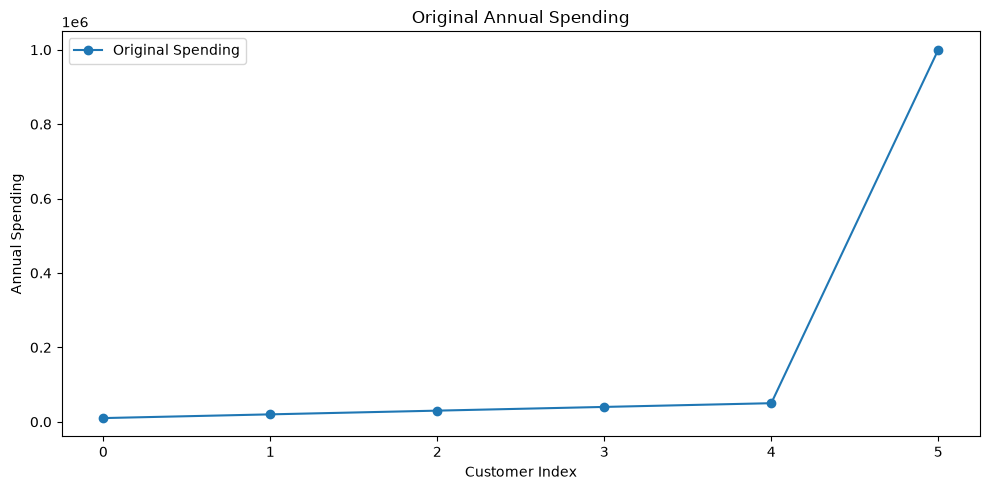

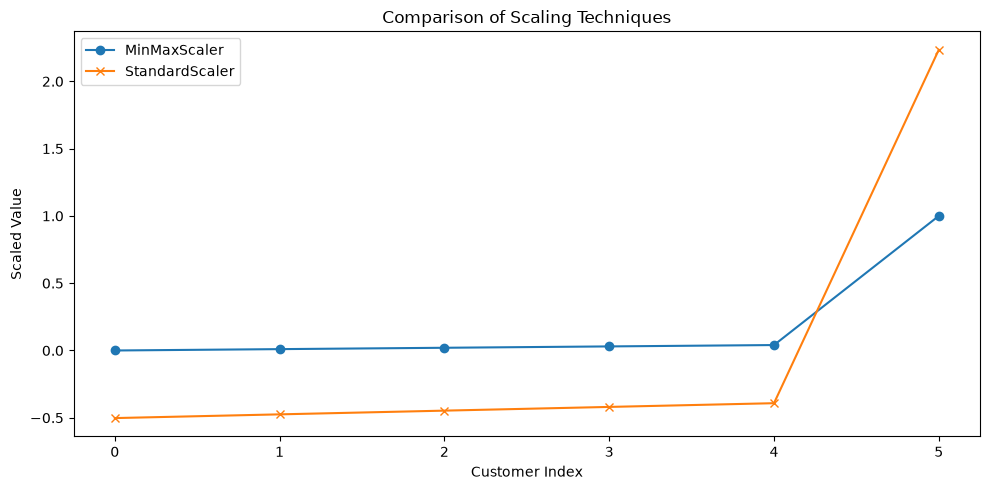

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    Normalizer
)

# Step 1: Create a sample dataset with an outlier
df = pd.DataFrame({
    "Age": [20, 25, 30, 35, 40, 45],
    "Annual_Spending": [10000, 20000, 30000, 40000, 50000, 1000000]
})

print("Original Dataset:")
print(df)

# Step 2: Apply StandardScaler
standard_scaler = StandardScaler()

standard_scaled = standard_scaler.fit_transform(df)

standard_df = pd.DataFrame(
    standard_scaled,
    columns=["Age_Standard", "Spending_Standard"]
)

print("\nStandardScaler Output:")
print(standard_df)

# Step 3: Apply MinMaxScaler
minmax_scaler = MinMaxScaler()

minmax_scaled = minmax_scaler.fit_transform(df)

minmax_df = pd.DataFrame(
    minmax_scaled,
    columns=["Age_MinMax", "Spending_MinMax"]
)

print("\nMinMaxScaler Output:")
print(minmax_df)

# Step 4: Apply RobustScaler
robust_scaler = RobustScaler()

robust_scaled = robust_scaler.fit_transform(df)

robust_df = pd.DataFrame(
    robust_scaled,
    columns=["Age_Robust", "Spending_Robust"]
)

print("\nRobustScaler Output:")
print(robust_df)

# Step 5: Apply MaxAbsScaler
maxabs_scaler = MaxAbsScaler()

maxabs_scaled = maxabs_scaler.fit_transform(df)

maxabs_df = pd.DataFrame(
    maxabs_scaled,
    columns=["Age_MaxAbs", "Spending_MaxAbs"]
)

print("\nMaxAbsScaler Output:")
print(maxabs_df)

# Step 6: Compare the Annual Spending feature
comparison_df = pd.DataFrame({
    "Original": df["Annual_Spending"],
    "StandardScaler": standard_df["Spending_Standard"],
    "MinMaxScaler": minmax_df["Spending_MinMax"],
    "RobustScaler": robust_df["Spending_Robust"],
    "MaxAbsScaler": maxabs_df["Spending_MaxAbs"]
})

print("\nScaling Technique Comparison:")
print(comparison_df.round(3))

# Step 7: Demonstrate unit-norm normalization
# Normalizer operates on rows, not independently on each column.
normalizer = Normalizer(norm="l2")

unit_norm_scaled = normalizer.fit_transform(df)

unit_norm_df = pd.DataFrame(
    unit_norm_scaled,
    columns=["Age_UnitNorm", "Spending_UnitNorm"]
)

print("\nUnit-Norm Normalization:")
print(unit_norm_df.round(4))

# Step 8: Demonstrate the effect of an outlier on Min-Max scaling
spending_without_extreme = pd.DataFrame({
    "Annual_Spending": [10000, 20000, 30000, 40000, 50000]
})

minmax_without_extreme = MinMaxScaler()

scaled_without_extreme = minmax_without_extreme.fit_transform(
    spending_without_extreme
).ravel()

minmax_with_extreme = MinMaxScaler()

scaled_with_extreme = minmax_with_extreme.fit_transform(
    df[["Annual_Spending"]]
).ravel()

outlier_comparison = pd.DataFrame({
    "Spending": spending_without_extreme["Annual_Spending"],
    "MinMax_Without_Extreme": scaled_without_extreme,
    "MinMax_With_Extreme": scaled_with_extreme[:5]
})

print("\nEffect of an Outlier on Min-Max Scaling:")
print(outlier_comparison.round(4))

# Step 9: Visualize original and scaled spending
plt.figure(figsize=(10, 5))

plt.plot(
    df.index,
    df["Annual_Spending"],
    marker="o",
    label="Original Spending"
)

plt.xlabel("Customer Index")
plt.ylabel("Annual Spending")
plt.title("Original Annual Spending")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    df.index,
    minmax_df["Spending_MinMax"],
    marker="o",
    label="MinMaxScaler"
)

plt.plot(
    df.index,
    standard_df["Spending_Standard"],
    marker="x",
    label="StandardScaler"
)

plt.xlabel("Customer Index")
plt.ylabel("Scaled Value")
plt.title("Comparison of Scaling Techniques")
plt.legend()
plt.tight_layout()
plt.show()